In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path('../data')
CACHE = DATA / 'cache'
cleaned_papers = pd.read_parquet(DATA / 'papers_cleaned.gencat.parquet')

cleaned_papers['orcidResearchers'] = cleaned_papers['orcidResearchers'].str.split(';')

In [8]:
cleaned_papers['date'] = pd.to_datetime(cleaned_papers['date'])

In [9]:
year_df = cleaned_papers[cleaned_papers['date'].dt.year == 2022]
exploded_papers = year_df.explode('orcidResearchers')
grouped = exploded_papers['orcidResearchers'].value_counts()

grouped

orcidResearchers
0000-0002-0548-0053    1196
0000-0003-3232-4598    1014
0000-0002-7215-0150     908
0000-0003-1260-4445     904
0000-0002-3130-0204     898
                       ... 
0000-0002-8288-1475       1
0000-0002-1152-7444       1
0000-0001-7711-846X       1
0000-0001-9309-5413       1
0000-0002-6291-3644       1
Name: count, Length: 17291, dtype: int64

In [13]:
vc = grouped.value_counts().sort_index()            # counts per value, ascending x

dif = pd.DataFrame({
    "value": vc.index,
    "count": vc.values,
})
dif["cdf"]   = dif["count"].cumsum() / dif["count"].sum()
dif["surv"]  = 1 - dif["cdf"]                 # this is what you plot
# optional: "fraction >= x" instead of "> x"
dif["surv_ge"] = dif["surv"] + dif["count"] / dif["count"].sum()

In [14]:
dif

,value,count,cdf,surv,surv_ge
0,1,1484,0.085825,0.914175,1.000000
1,2,1167,0.153317,0.846683,0.914175
2,3,660,0.191487,0.808513,0.846683
3,4,702,0.232086,0.767914,0.808513
4,5,502,0.261119,0.738881,0.767914
...,...,...,...,...,...
372,898,1,0.999769,0.000231,0.000289
373,904,1,0.999826,0.000174,0.000231
374,908,1,0.999884,0.000116,0.000174
375,1014,1,0.999942,0.000058,0.000116


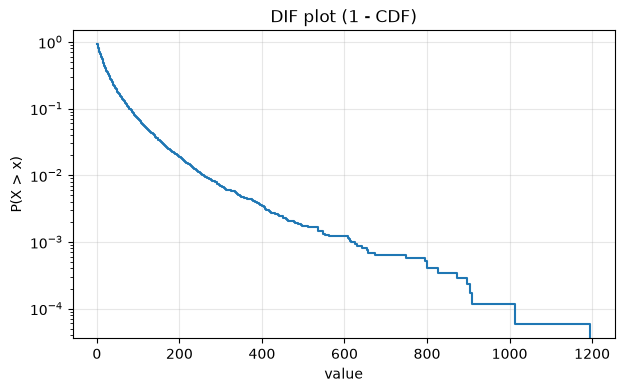

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.step(dif["value"], dif["surv"], where="post")
ax.set_xlabel("value")
ax.set_ylabel("P(X > x)")
ax.set_title("DIF plot (1 - CDF)")
# ax.set_ylim(0, 1)
ax.grid(alpha=0.3)
# ax.set_xscale("log")
ax.set_yscale("log")
plt.show()